# Module 0: Setup and tooling

Goal: prove the environment works end to end.

1. Import the `statarb` package (installed in editable mode by `uv sync`).
2. Download one ticker from Yahoo Finance.
3. Plot it.
4. Cache it to `data/` (git-ignored) and confirm that a second load reads the cache.

Lecture notes: [`lecture.md`](lecture.md).

In [1]:
import time

import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

import statarb
from statarb import config

print("statarb", statarb.__version__)
print("trading days per year:", config.TRADING_DAYS)
print("data cache:", config.RAW_DIR.relative_to(config.PROJECT_ROOT))

statarb 0.1.0
trading days per year: 252
data cache: data/raw


## A minimal cache

Module 1 replaces this with `statarb.data.load_prices`. For now, a few lines show the idea:
download once, store as parquet, and read from disk afterwards. We also record *when* the
data was downloaded, because Yahoo revises history.

In [2]:
TICKER = "SPY"
cache_file = config.RAW_DIR / f"m0_{TICKER}.parquet"


def load_spy() -> tuple[pd.DataFrame, str]:
    if cache_file.exists():
        return pd.read_parquet(cache_file), "cache"
    bars = yf.Ticker(TICKER).history(start="2015-01-01", end="2025-01-01", auto_adjust=False)
    bars.index = bars.index.tz_localize(None).normalize()
    bars.attrs["downloaded_at"] = pd.Timestamp.now(tz="UTC").isoformat()
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    bars.to_parquet(cache_file)
    return bars, "download"


cache_file.unlink(missing_ok=True)  # start clean so both paths run
for attempt in (1, 2):
    t0 = time.perf_counter()
    bars, source = load_spy()
    print(f"load {attempt}: {source:8s} {time.perf_counter() - t0:6.3f} s, {len(bars)} rows")

load 1: download  0.268 s, 2516 rows
load 2: cache     0.009 s, 2516 rows


In [3]:
bars.head()

,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Capital Gains
Date,,,,,,,,,
2015-01-02,206.380005,206.880005,204.179993,205.429993,169.267517,121465900,0.0,0.0,0.0
2015-01-05,204.169998,204.369995,201.350006,201.720001,166.210587,169632600,0.0,0.0,0.0
2015-01-06,202.089996,202.720001,198.860001,199.820007,164.645050,209151400,0.0,0.0,0.0
2015-01-07,201.419998,202.720001,200.880005,202.309998,166.696777,125346700,0.0,0.0,0.0
2015-01-08,204.009995,206.160004,203.990005,205.899994,169.654755,147217800,0.0,0.0,0.0


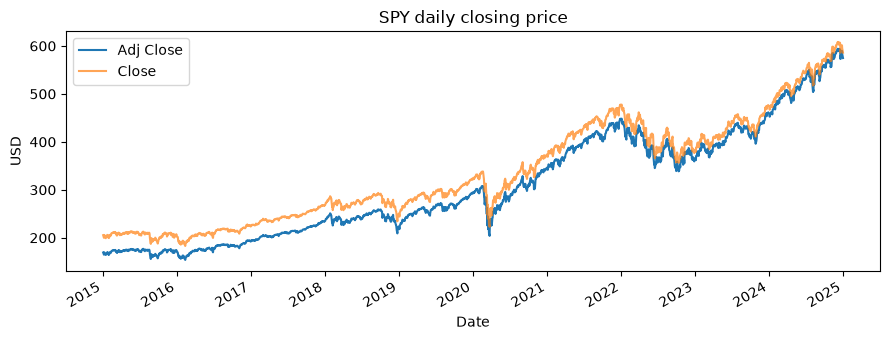

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
bars["Adj Close"].plot(ax=ax, label="Adj Close")
bars["Close"].plot(ax=ax, label="Close", alpha=0.7)
ax.set_title(f"{TICKER} daily closing price")
ax.set_ylabel("USD")
ax.legend()
fig.tight_layout()

The two lines diverge going back in time: `Adj Close` folds in the dividends SPY paid, so its
history is scaled down. Module 1 explains why backtests must use the adjusted series.

## Checklist (Module 0 "done when")

- `uv run pytest` and `uv run ruff check` pass locally and in GitHub Actions.
- `uv run jupyter lab` opens this notebook and `import statarb` works.